# Complaint2Concern
## Using pretrained complaint embeddings to catch acuity-relevant risk that structured triage may miss

### Clinical motivation
- Emergency triage decisions are safety-critical, and undertriage is often the most harmful error type.
- Structured intake fields are useful but may miss concern signals present in free-text chief complaint language.
- We use pretrained complaint embeddings as a second clinical lens and analyze disagreement with structured-only predictions.

### Hypothesis
Pretrained complaint embeddings improve acuity prediction and help identify cases where free text suggests more urgency than structured intake alone.

### Core questions
1. Does complaint text improve triage acuity prediction beyond structured features?
2. Which complaint clusters are associated with higher acuity?
3. Can text-vs-structure disagreement identify review-worthy cases?

## Data understanding and leakage guardrails

This is a triage-time task. All model inputs must be available at triage decision time.

- Allowed: intake structured variables, chief complaint text, prior history available at triage.
- Excluded as leakage: post-triage outcomes (for example `disposition`, `ed_los_hours`).

Missingness is handled with model pipelines (median/mode imputation in structured preprocessing).

In [6]:
import os
import re
import sys
from pathlib import Path

import numpy as np
import pandas as pd

from scipy.sparse import csr_matrix, hstack
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

try:
    import matplotlib.pyplot as plt
    MATPLOTLIB_OK = True
except Exception:
    MATPLOTLIB_OK = False

# Resolve project root (works in local Jupyter and in Kaggle if repo is copied).
candidates = [Path.cwd(), Path.cwd().parent]
PROJECT_ROOT = None
for c in candidates:
    if (c / 'src').exists() and (c / 'configs').exists():
        PROJECT_ROOT = c
        break
if PROJECT_ROOT is None:
    raise RuntimeError('Could not locate PROJECT_ROOT with src/ and configs/.')

sys.path.append(str(PROJECT_ROOT))
print('PROJECT_ROOT:', PROJECT_ROOT)

Matplotlib is building the font cache; this may take a moment.


PROJECT_ROOT: /Users/raquel_romao/Documents/3AIG_TriageKeggleCompetition/3AIG


In [7]:
from src.config import load_config
from src.data_io import load_train_test
from src.embeddings import encode_complaints
from src.features_structured import fit_transform_structured, infer_structured_columns
from src.features_text import fit_transform_tfidf
from src.preprocess import preprocess_text_series
from src.utils import make_classifier, set_seed

In [8]:
# Config
cfg = load_config(PROJECT_ROOT / 'configs/minilm_catboost.yaml')

# Optional Kaggle path override example:
# cfg['data']['kaggle_input_dir'] = '/kaggle/input/triagegeist'

DEV_SAMPLE_N = None  # Set an integer like 20000 for quick local iteration.
SEED = cfg['train'].get('seed', 42)
set_seed(SEED)

train_df, test_df = load_train_test(cfg)
if DEV_SAMPLE_N is not None and DEV_SAMPLE_N < len(train_df):
    train_df = train_df.sample(DEV_SAMPLE_N, random_state=SEED).reset_index(drop=True)

id_col = cfg['data']['id_col']
target_col = cfg['data']['target_col']
text_col = cfg['data']['text_col']
leakage_cols = cfg['data'].get('leakage_columns', [])

print('train shape:', train_df.shape)
print('test shape :', test_df.shape)
print('target col :', target_col)
print('text col   :', text_col)
print('null text train:', round(train_df[text_col].isna().mean(), 4))
print('null text test :', round(test_df[text_col].isna().mean(), 4))

train shape: (80000, 66)
test shape : (20000, 63)
target col : triage_acuity
text col   : chief_complaint_raw
null text train: 0.0
null text test : 0.0


Acuity distribution (train):


triage_acuity
1    0.040275
2    0.167988
3    0.361513
4    0.287750
5    0.142475
Name: proportion, dtype: float64

,missing_rate
shock_index,0.051825
pulse_pressure,0.051825
systolic_bp,0.051825
diastolic_bp,0.051825
mean_arterial_pressure,0.051825
respiratory_rate,0.038337
temperature_c,0.007175
hx_diabetes_type2,0.000000
hx_diabetes_type1,0.000000
disposition,0.000000


,heart_rate,respiratory_rate,temperature_c,spo2,systolic_bp,diastolic_bp,news2_score
triage_acuity,,,,,,,
1,119.2,28.0,38.9,85.9,82.6,52.15,14.0
2,108.7,23.0,38.5,92.0,100.4,63.30,10.0
3,93.0,18.0,37.7,96.0,126.0,76.90,2.0
4,84.1,16.0,37.2,98.0,132.0,80.00,0.0
5,76.8,15.0,36.9,99.0,128.1,78.80,0.0


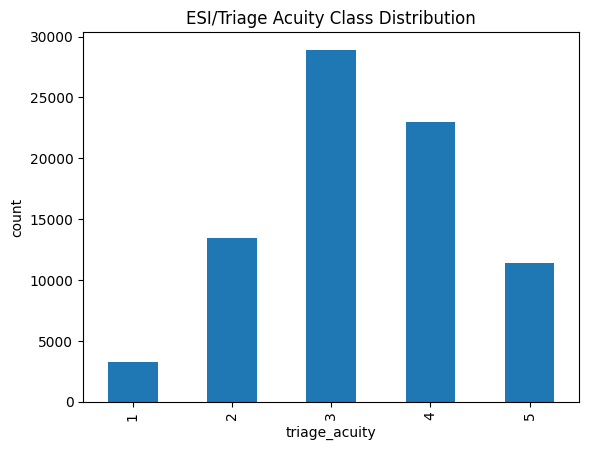

In [9]:
# Triage-focused EDA
print('Acuity distribution (train):')
display(train_df[target_col].value_counts(normalize=True).sort_index())

missingness = train_df.isna().mean().sort_values(ascending=False)
display(missingness.head(15).to_frame('missing_rate'))

# Vitals by acuity (median)
vitals = [c for c in ['heart_rate','respiratory_rate','temperature_c','spo2','systolic_bp','diastolic_bp','news2_score'] if c in train_df.columns]
if vitals:
    display(train_df.groupby(target_col)[vitals].median())

if MATPLOTLIB_OK:
    ax = train_df[target_col].value_counts().sort_index().plot(kind='bar', title='ESI/Triage Acuity Class Distribution')
    ax.set_xlabel('triage_acuity')
    ax.set_ylabel('count')
    plt.show()

## Complaint text preprocessing

We keep preprocessing lightweight and realistic for triage text:
- lowercase
- punctuation and whitespace cleanup
- optional normalization of common abbreviations
- keep most spelling noise intact to preserve realistic inputs

In [ ]:
ABBREV_MAP = {
    'sob': 'shortness of breath',
    'cp': 'chest pain',
    'ha': 'headache',
    'n/v': 'nausea vomiting',
}

def normalize_abbrev(text: str) -> str:
    t = '' if text is None else str(text).lower()
    for k, v in ABBREV_MAP.items():
        t = re.sub(rf'\b{re.escape(k)}\b', v, t)
    return t

train_df[text_col] = train_df[text_col].fillna('').map(normalize_abbrev)
test_df[text_col] = test_df[text_col].fillna('').map(normalize_abbrev)

display(train_df[[text_col]].head(10))

In [ ]:
# Prepare split
label_encoder = LabelEncoder()
y_all = label_encoder.fit_transform(train_df[target_col].astype(str))

train_idx, valid_idx = train_test_split(
    np.arange(len(train_df)),
    test_size=cfg['train'].get('valid_size', 0.2),
    random_state=SEED,
    stratify=y_all,
)

tr = train_df.iloc[train_idx].reset_index(drop=True)
va = train_df.iloc[valid_idx].reset_index(drop=True)
y_tr = y_all[train_idx]
y_va = y_all[valid_idx]

print('train split:', tr.shape)
print('valid split:', va.shape)

In [ ]:
# Structured feature preprocessing
structured_cols = infer_structured_columns(
    tr,
    target_col=target_col,
    text_col=text_col,
    id_col=id_col,
    explicit_drop_cols=leakage_cols,
)

structured_pre, x_tr_struct, x_va_struct = fit_transform_structured(tr[structured_cols], va[structured_cols])
print('structured feature count:', x_tr_struct.shape[1])

## Baselines and fusion models

We train and compare:
1. Structured-only
2. Text-only (TF-IDF + linear model)
3. Structured + TF-IDF
4. Text-only pretrained embeddings
5. Structured + pretrained embeddings (Complaint2Concern fusion)

In [ ]:
# 1) Structured-only
structured_model = make_classifier(
    model_name='catboost',
    params={'iterations': 350, 'depth': 6, 'learning_rate': 0.05, 'verbose': False},
    n_classes=len(label_encoder.classes_),
)
structured_model.fit(x_tr_struct, y_tr)
pred_struct = np.asarray(structured_model.predict(x_va_struct)).reshape(-1).astype(int)
proba_struct = np.asarray(structured_model.predict_proba(x_va_struct))

# 2) Text-only TF-IDF + linear model
tfidf_vec, x_tr_tfidf, x_va_tfidf = fit_transform_tfidf(
    tr[text_col],
    va[text_col],
    max_features=25000,
    ngram_range=(1, 2),
)
tfidf_model = LogisticRegression(max_iter=1200, multi_class='multinomial', n_jobs=-1)
tfidf_model.fit(x_tr_tfidf, y_tr)
pred_tfidf = tfidf_model.predict(x_va_tfidf).astype(int)
proba_tfidf = tfidf_model.predict_proba(x_va_tfidf)

# 3) Structured + TF-IDF
x_tr_struct_sparse = csr_matrix(x_tr_struct)
x_va_struct_sparse = csr_matrix(x_va_struct)
x_tr_struct_tfidf = hstack([x_tr_struct_sparse, x_tr_tfidf]).tocsr()
x_va_struct_tfidf = hstack([x_va_struct_sparse, x_va_tfidf]).tocsr()
struct_tfidf_model = LogisticRegression(max_iter=1200, multi_class='multinomial', n_jobs=-1)
struct_tfidf_model.fit(x_tr_struct_tfidf, y_tr)
pred_struct_tfidf = struct_tfidf_model.predict(x_va_struct_tfidf).astype(int)
proba_struct_tfidf = struct_tfidf_model.predict_proba(x_va_struct_tfidf)

In [ ]:
# 4) Text-only pretrained embeddings
emb_model_name = cfg['embeddings'].get('model_name', 'sentence-transformers/all-MiniLM-L6-v2')
emb_batch_size = cfg['embeddings'].get('batch_size', 64)

x_tr_emb = encode_complaints(tr[text_col], model_name=emb_model_name, batch_size=emb_batch_size)
x_va_emb = encode_complaints(va[text_col], model_name=emb_model_name, batch_size=emb_batch_size)

emb_text_model = make_classifier(
    model_name='lightgbm',
    params={'n_estimators': 350, 'learning_rate': 0.05, 'num_leaves': 63},
    n_classes=len(label_encoder.classes_),
)
emb_text_model.fit(x_tr_emb, y_tr)
pred_emb_text = np.asarray(emb_text_model.predict(x_va_emb)).reshape(-1).astype(int)
proba_emb_text = np.asarray(emb_text_model.predict_proba(x_va_emb))

# 5) Structured + pretrained embeddings (main fusion)
x_tr_fusion = np.hstack([x_tr_struct, x_tr_emb])
x_va_fusion = np.hstack([x_va_struct, x_va_emb])
fusion_model = make_classifier(
    model_name='catboost',
    params={'iterations': 450, 'depth': 6, 'learning_rate': 0.05, 'verbose': False},
    n_classes=len(label_encoder.classes_),
)
fusion_model.fit(x_tr_fusion, y_tr)
pred_fusion = np.asarray(fusion_model.predict(x_va_fusion)).reshape(-1).astype(int)
proba_fusion = np.asarray(fusion_model.predict_proba(x_va_fusion))

In [ ]:
# ESI-aware evaluation helpers
def decode(enc):
    return label_encoder.inverse_transform(np.asarray(enc).astype(int))

def to_int_labels(labels):
    return np.asarray(labels).astype(int)

def off_by_one_acc(y_true_int, y_pred_int):
    return float(np.mean(np.abs(y_true_int - y_pred_int) <= 1))

def eval_esi(y_true_enc, y_pred_enc):
    y_true_int = to_int_labels(decode(y_true_enc))
    y_pred_int = to_int_labels(decode(y_pred_enc))
    return {
        'accuracy': float(np.mean(y_true_enc == y_pred_enc)),
        'macro_f1': float(f1_score(y_true_enc, y_pred_enc, average='macro')),
        'off_by_1': off_by_one_acc(y_true_int, y_pred_int),
        'undertriage_rate': float(np.mean(y_pred_int > y_true_int)),
        'severe_undertriage_rate': float(np.mean((y_pred_int - y_true_int) >= 2)),
        'recall_esi_1_2': float(np.mean(y_pred_int[y_true_int <= 2] <= 2)) if np.any(y_true_int <= 2) else np.nan,
    }

rows = [
    {'model': 'structured_only', **eval_esi(y_va, pred_struct)},
    {'model': 'text_tfidf_only', **eval_esi(y_va, pred_tfidf)},
    {'model': 'structured_plus_tfidf', **eval_esi(y_va, pred_struct_tfidf)},
    {'model': 'text_emb_only', **eval_esi(y_va, pred_emb_text)},
    {'model': 'structured_plus_emb_fusion', **eval_esi(y_va, pred_fusion)},
]
perf_df = pd.DataFrame(rows).sort_values('macro_f1', ascending=False)
display(perf_df)

In [ ]:
# Confusion matrix (fusion)
y_true_int = to_int_labels(decode(y_va))
y_pred_fusion_int = to_int_labels(decode(pred_fusion))
cm = pd.crosstab(
    pd.Series(y_true_int, name='true_acuity'),
    pd.Series(y_pred_fusion_int, name='pred_acuity'),
    dropna=False,
)
display(cm)

## Innovation layer: complaint-structure mismatch

We define a Text Concern Gap using high-acuity probability mass (ESI 1-2):

`gap = P_text(ESI 1-2) - P_structured(ESI 1-2)`

Positive values indicate text model is more alarmed than structured-only model.

In [ ]:
classes_int = np.asarray(label_encoder.classes_).astype(int)
high_mask = classes_int <= 2

p_high_text = proba_emb_text[:, high_mask].sum(axis=1)
p_high_struct = proba_struct[:, high_mask].sum(axis=1)
concern_gap = p_high_text - p_high_struct

mismatch_df = va[[id_col, text_col]].copy()
mismatch_df['true_acuity'] = y_true_int
mismatch_df['pred_structured'] = to_int_labels(decode(pred_struct))
mismatch_df['pred_text_emb'] = to_int_labels(decode(pred_emb_text))
mismatch_df['pred_fusion'] = y_pred_fusion_int
mismatch_df['p_high_text'] = p_high_text
mismatch_df['p_high_struct'] = p_high_struct
mismatch_df['text_concern_gap'] = concern_gap

gap_threshold = np.quantile(mismatch_df['text_concern_gap'], 0.90)
alert_cases = mismatch_df[mismatch_df['text_concern_gap'] >= gap_threshold].copy()

print('gap threshold (p90):', round(float(gap_threshold), 4))
print('alert case count:', len(alert_cases))
print('alert true high-acuity rate:', round((alert_cases['true_acuity'] <= 2).mean(), 4))

display(alert_cases.sort_values('text_concern_gap', ascending=False).head(20))

In [ ]:
# Complaint clustering and interpretation
n_clusters = 8
kmeans = KMeans(n_clusters=n_clusters, random_state=SEED, n_init=10)
cluster_id = kmeans.fit_predict(x_va_emb)

cluster_df = va[[text_col]].copy()
cluster_df['cluster'] = cluster_id
cluster_df['true_acuity'] = y_true_int
cluster_df['text_concern_gap'] = concern_gap

cluster_summary = cluster_df.groupby('cluster').agg(
    n=('cluster', 'size'),
    high_acuity_rate=('true_acuity', lambda s: np.mean(s <= 2)),
    mean_text_concern_gap=('text_concern_gap', 'mean'),
).sort_values('high_acuity_rate', ascending=False)
display(cluster_summary)

# Representative complaints: first few examples per cluster
examples = (
    cluster_df.groupby('cluster')[text_col]
    .apply(lambda s: list(s.head(5)))
    .to_frame('sample_complaints')
)
display(examples)

cluster_esi = pd.crosstab(cluster_df['cluster'], cluster_df['true_acuity'], normalize='index')
display(cluster_esi)

In [ ]:
# Review-flag logic (support tool, not auto-overrule)
pmax_fusion = proba_fusion.max(axis=1)
low_conf_threshold = np.quantile(pmax_fusion, 0.10)
high_gap_threshold = np.quantile(concern_gap, 0.90)

mismatch_df['fusion_confidence'] = pmax_fusion
mismatch_df['review_flag'] = (
    (mismatch_df['fusion_confidence'] <= low_conf_threshold)
    | (mismatch_df['text_concern_gap'] >= high_gap_threshold)
)

flagged = mismatch_df[mismatch_df['review_flag']]
print('review flag rate:', round(len(flagged) / len(mismatch_df), 4))
print('high-acuity rate among flagged:', round((flagged['true_acuity'] <= 2).mean(), 4))
display(flagged.head(20))

In [ ]:
# Robustness quick checks: typo and truncation perturbations
def perturb_typo(s: str) -> str:
    t = '' if s is None else str(s)
    if len(t) < 5:
        return t
    return t[:-1] + 'x'

def perturb_short(s: str) -> str:
    t = '' if s is None else str(s)
    return ' '.join(t.split()[:2])

rob_n = min(2000, len(va))
rob_text = va[text_col].head(rob_n).tolist()
rob_typo = [perturb_typo(x) for x in rob_text]
rob_short = [perturb_short(x) for x in rob_text]

rob_emb = encode_complaints(rob_text, model_name=emb_model_name, batch_size=emb_batch_size)
rob_typo_emb = encode_complaints(rob_typo, model_name=emb_model_name, batch_size=emb_batch_size)
rob_short_emb = encode_complaints(rob_short, model_name=emb_model_name, batch_size=emb_batch_size)

rob_struct = x_va_struct[:rob_n]
pred_base = np.asarray(fusion_model.predict(np.hstack([rob_struct, rob_emb]))).reshape(-1).astype(int)
pred_typo = np.asarray(fusion_model.predict(np.hstack([rob_struct, rob_typo_emb]))).reshape(-1).astype(int)
pred_short = np.asarray(fusion_model.predict(np.hstack([rob_struct, rob_short_emb]))).reshape(-1).astype(int)

print('stability vs typo perturbation:', round(float(np.mean(pred_base == pred_typo)), 4))
print('stability vs shortened complaint:', round(float(np.mean(pred_base == pred_short)), 4))

In [ ]:
# Fairness / subgroup snapshot on validation split
subgroups = [c for c in ['age_group', 'sex', 'site_id'] if c in va.columns]
subgroup_rows = []
for col in subgroups:
    temp = va[[col]].copy()
    temp['y_true'] = y_true_int
    temp['y_pred'] = y_pred_fusion_int
    for grp, gdf in temp.groupby(col):
        if len(gdf) < 50:
            continue
        subgroup_rows.append({
            'group_col': col,
            'group_val': grp,
            'n': len(gdf),
            'accuracy': float(np.mean(gdf['y_true'] == gdf['y_pred'])),
            'undertriage_rate': float(np.mean(gdf['y_pred'] > gdf['y_true'])),
        })
subgroup_df = pd.DataFrame(subgroup_rows).sort_values(['group_col', 'n'], ascending=[True, False])
display(subgroup_df.head(30))

## Export final submission

We train fusion on full training data, predict test acuity, and write a Kaggle-ready CSV.

In [ ]:
# Refit fusion pipeline on full training data for submission
y_full = label_encoder.fit_transform(train_df[target_col].astype(str))
full_struct_cols = infer_structured_columns(
    train_df,
    target_col=target_col,
    text_col=text_col,
    id_col=id_col,
    explicit_drop_cols=leakage_cols,
)

full_pre, x_train_struct_full, x_test_struct = fit_transform_structured(
    train_df[full_struct_cols],
    test_df[full_struct_cols],
)
x_train_emb_full = encode_complaints(train_df[text_col], model_name=emb_model_name, batch_size=emb_batch_size)
x_test_emb = encode_complaints(test_df[text_col], model_name=emb_model_name, batch_size=emb_batch_size)

x_train_fusion_full = np.hstack([x_train_struct_full, x_train_emb_full])
x_test_fusion = np.hstack([x_test_struct, x_test_emb])

final_fusion_model = make_classifier(
    model_name='catboost',
    params={'iterations': 450, 'depth': 6, 'learning_rate': 0.05, 'verbose': False},
    n_classes=len(label_encoder.classes_),
)
final_fusion_model.fit(x_train_fusion_full, y_full)
test_pred_enc = np.asarray(final_fusion_model.predict(x_test_fusion)).reshape(-1).astype(int)
test_pred = label_encoder.inverse_transform(test_pred_enc)

submission = pd.DataFrame({id_col: test_df[id_col], target_col: test_pred})
submission[target_col] = submission[target_col].astype(int)

out_dir = PROJECT_ROOT / 'outputs'
out_dir.mkdir(parents=True, exist_ok=True)
submission_path = out_dir / 'submission_notebook.csv'
submission.to_csv(submission_path, index=False)
print('saved:', submission_path)
display(submission.head())

## Deployment concept (triage support, not replacement)

1. Nurse enters structured triage intake and chief complaint text.
2. System outputs acuity suggestion with confidence and concern-gap signal.
3. Large text-vs-structure disagreement or low confidence triggers a review flag.
4. Final decision remains with clinician; tool supports consistency and safety awareness.